<a href="https://colab.research.google.com/github/ayanrasulova/ds2002-midterm/blob/main/checkpoints/2026_10_23_%E2%80%94_Midterm_Checkpoint_%E2%80%94_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Checkpoint

**Lab — 2026-10-23 · Fall 2026**  

---

## Lab 09 — Midterm checkpoint, week 1 of 3

One submission per team. These are the same eight things we listed at Monday's kickoff. This is graded on evidence, not on intentions — every section below wants code that ran and output you can point at.

The purpose is to catch a stalled team while there is still time to unstall it. If something is not working, say so here plainly. A checkpoint that honestly reports "the API join is not working and here is the error" is worth more than one that claims progress that does not exist, and it gets you help on Monday.

### 1 — Your cleaning pipeline as functions

**TODO:** paste the cleaning code you have written so far. It should be functions, not loose cells, and it should cover at minimum: duplicates, `unit_price` to numeric (it comes in as text, some with a `$`), the negative `quantity` values with your decision applied, `timestamp` parsed, and `store_id` cleaned up so it will join to the store file.

Print the row count before and after. We want to see how many rows your decisions removed.

In [17]:
from pathlib import Path
import re

import pandas as pd

# find the project data folder, or in Colab
possible_data_dirs = [
    Path.cwd() / "data",
    Path.cwd().parent / "data",
    Path("/content/data"),
]
if Path("/content").is_dir():
    possible_data_dirs.extend(Path("/content").glob("**/data"))
DATA_DIR = next((path for path in possible_data_dirs if path.is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError("could not find the data folder")
#read in data as plain text to avoid automatic conversion by Pandas
raw_transactions = pd.read_csv(
    DATA_DIR / "walmart_transactions.csv", dtype="string", keep_default_na=False
)
raw_stores = pd.read_csv(
    DATA_DIR / "store_locations.csv", dtype="string", keep_default_na=False
)
raw_products = pd.read_csv(
    DATA_DIR / "product_catalog.csv", dtype="string", keep_default_na=False
)

missing_tokens = {"", "NULL", "N/A", "NA", "NAN", "NONE"}
sku_groups = {
    "PT-12": ["PT-12", "SKU#459812", "POPTART-STRAW", "PT_STRAWBERRY"],
    "WTR-24": ["WTR-24", "WATER24PK", "WTR_24PK"],
    "BATT-100": ["BATT-100", "BAT-AA4", "BATT_AA_4PK"],
    "FLASH-01": ["FLASH-01", "LED-FLASH"],
    "BEER-24": ["BEER-24", "LTBEER24"],
    "BG-MONO": ["BG-MONO", "MONOPOLY-01", "GAME-MONO"],
    "CARDS-01": ["CARDS-01", "PLAYCARD-STD"],
    "STREAM-01": ["STREAM-01", "ROKU-STD"],
    "SOUP-CAN": ["SOUP-CAN", "CNSOUP-01"],
    "BREAD-WH": ["BREAD-WH", "WHITEBREAD"],
    "PB-16": ["PB-16", "PNUTBTR-16"],
    "CNDL-EM": ["CNDL-EM", "CANDLE-EMRG"],
    "FAID-01": ["FAID-01", "FIRSTAID-KIT"],
    "CHRG-PORT": ["CHRG-PORT", "PORTCHARGER"],
    "CHIPS-VP": ["CHIPS-VP", "CHIPVARIETY"],
    "PTOWEL-6": ["PTOWEL-6", "PAPERTOWEL6"],
    "TP-12": ["TP-12", "TOILETPAPER12"],
    "DIAP-S3": ["DIAP-S3", "DIAPERS-3"],
    "BFORM-01": ["BFORM-01", "BABYFORMULA"],
    "TARP-HD": ["TARP-HD", "HDTARP-01"],
}
# create a mapping of all known aliases to their canonical sku
sku_to_canonical = {
    alias.upper(): canonical
    for canonical, aliases in sku_groups.items()
    for alias in aliases
}
# standardize store ids and make empty strings and null-like values missing
def normalize_missing(frame):
    cleaned = frame.copy()
    for column in cleaned.select_dtypes(include=["object", "string"]).columns:
        values = cleaned[column].astype("string").str.strip()
        cleaned[column] = values.mask(values.str.upper().isin(missing_tokens), pd.NA)
    return cleaned

# standardize stores ids so they are all in 'FL' format to join
def normalize_store_id(values):
    text = values.astype("string").str.strip().str.upper()
    digits = text.str.extract(r"^FL[\s_-]?(\d{3})$", expand=False)
    return text.where(digits.isna(), "FL-" + digits)

# map spelling variations and capitalization to a canonical category name
def normalize_category(values):
    text = values.astype("string").str.strip().str.replace(r"\s+", " ", regex=True)
    key = text.str.casefold().str.replace(r"[^a-z0-9]", "", regex=True)
    category_names = {
        "breakfastfoods": "Breakfast", "breakfast": "Breakfast",
        "emergencysupplies": "Emergency", "emergency": "Emergency",
        "alcoholicbeverages": "Alcohol", "alcohol": "Alcohol",
        "groceries": "Grocery", "grocery": "Grocery",
        "householdessentials": "Household", "household": "Household",
        "babyproducts": "Baby", "baby": "Baby",
        "entertainment": "Entertainment", "electronics": "Electronics",
        "health": "Health", "snacks": "Snacks",
    }
    return key.map(category_names).fillna(text.str.title()).astype("string")

#convert numeric fields to numbers, removing currency symbols and commas
def to_number(values):
    text = values.astype("string").str.strip().str.replace(r"[$,~]", "", regex=True)
    return pd.to_numeric(text, errors="coerce")

def clean_transactions(transaction_data, store_data):
    before_rows = len(transaction_data)
    transactions = normalize_missing(transaction_data)
    missing_rows = int(transactions.isna().any(axis=1).sum())

    # keep the first copy of each transaction id
    transactions["transaction_id"] = transactions["transaction_id"].str.strip().str.upper()
    before_dedup = len(transactions)
    transactions = transactions.drop_duplicates(subset=["transaction_id"], keep="first").copy()
    duplicate_rows = before_dedup - len(transactions)

#clean store values, drop duplicates
    stores = normalize_missing(store_data)
    old_store_ids = stores["store_id"].copy()
    stores["store_id"] = normalize_store_id(stores["store_id"])
    store_ids_changed = int(old_store_ids.ne(stores["store_id"]).fillna(False).sum())
    before_store_dedup = len(stores)
    stores = stores.drop_duplicates(subset=["store_id"], keep="first").copy()
    duplicate_stores = before_store_dedup - len(stores)

# clean store ids to match the cleaned store file
    old_transaction_store_ids = transactions["store_id"].copy()
    transactions["store_id"] = normalize_store_id(transactions["store_id"])
    transaction_store_ids_changed = int(
        old_transaction_store_ids.ne(transactions["store_id"]).fillna(False).sum()
    )

    transactions["source_sku"] = transactions["sku"].astype("string").str.strip().str.upper()
    transactions["canonical_sku"] = transactions["source_sku"].map(sku_to_canonical).fillna(
        transactions["source_sku"]
    )
    sku_rows_changed = int(
        transactions["source_sku"].ne(transactions["canonical_sku"]).fillna(False).sum()
    )
    old_categories = transactions["category"].copy()
    transactions["category"] = normalize_category(transactions["category"])
    category_rows_changed = int(
        old_categories.ne(transactions["category"]).fillna(False).sum()
    )
    transactions["quantity"] = to_number(transactions["quantity"])
    transactions["unit_price"] = to_number(transactions["unit_price"])
    numeric_rows_touched = int(
        (transactions["quantity"].notna() | transactions["unit_price"].notna()).sum()
    )

    # parse mixed dates and convert local times to utc
    parsed = pd.to_datetime(transactions["timestamp"], format="mixed", errors="coerce")
    if parsed.dt.tz is None:
        parsed = parsed.dt.tz_localize(
            "America/New_York", ambiguous="NaT", nonexistent="NaT"
        )
    transactions["timestamp_local"] = parsed
    transactions["timestamp_utc"] = parsed.dt.tz_convert("UTC")

    # keep negative quantities aside for review
    negative_mask = transactions["quantity"].lt(0).fillna(False)
    quarantined = transactions.loc[negative_mask].copy()
    cleaned = transactions.loc[~negative_mask].copy()
    cleaned = cleaned.merge(
        stores[["store_id", "store_name", "city", "state", "region"]],
        on="store_id", how="left", validate="many_to_one",
    )

    decisions = pd.DataFrame([
        {"decision": "missing values", "action": "kept null-like fields as missing", "rows_touched": missing_rows},
        {"decision": "duplicate transactions", "action": "kept first transaction id", "rows_touched": duplicate_rows},
        {"decision": "store ids", "action": "standardized transaction ids", "rows_touched": transaction_store_ids_changed},
        {"decision": "store file", "action": "standardized ids and removed duplicate stores", "rows_touched": store_ids_changed + duplicate_stores},
        {"decision": "sku aliases", "action": "mapped source skus to canonical skus", "rows_touched": sku_rows_changed},
        {"decision": "categories", "action": "standardized names and capitalization", "rows_touched": category_rows_changed},
        {"decision": "numeric fields", "action": "converted quantity and price to numbers", "rows_touched": numeric_rows_touched},
        {"decision": "timestamps", "action": "parsed and converted valid times to utc", "rows_touched": int(parsed.notna().sum())},
        {"decision": "missing timestamps", "action": "left unparsed times as missing", "rows_touched": int(parsed.isna().sum())},
        {"decision": "negative quantities", "action": "moved rows to transactions_quarantined", "rows_touched": len(quarantined)},
    ])
    return cleaned, quarantined, stores, decisions, before_rows
# run the cleaned pipeline and make sure messy rolls are removed
transactions_clean, transactions_quarantined, stores, decision_log, rows_before = clean_transactions(
    raw_transactions, raw_stores
)
print("rows before cleaning:", rows_before)
print("duplicate transaction rows removed:", int(decision_log.loc[decision_log["decision"] == "duplicate transactions", "rows_touched"].iloc[0]))
print("negative quantity rows quarantined:", len(transactions_quarantined))
print("rows after cleaning:", len(transactions_clean))

rows before cleaning: 25562
duplicate transaction rows removed: 30
negative quantity rows quarantined: 130
rows after cleaning: 25402


### 2 — Your decision log

**TODO:** every cleaning decision, what it did, and how many rows it touched. If your teammates disagree with one of these, note the disagreement — that is useful information, not a problem to hide.

In [18]:
display(decision_log)
print("decision log entries:", len(decision_log))
print("rows before cleaning:", rows_before)
print("rows after cleaning:", len(transactions_clean))

,decision,action,rows_touched
0,missing values,kept null-like fields as missing,886
1,duplicate transactions,kept first transaction id,30
2,store ids,standardized transaction ids,3607
3,store file,standardized ids and removed duplicate stores,4
4,sku aliases,mapped source skus to canonical skus,13884
5,categories,standardized names and capitalization,17805
6,numeric fields,converted quantity and price to numbers,25532
7,timestamps,parsed and converted valid times to utc,24648
8,missing timestamps,left unparsed times as missing,884
9,negative quantities,moved rows to transactions_quarantined,130


decision log entries: 10
rows before cleaning: 25562
rows after cleaning: 25402


### 3 — SKU consolidation progress

**TODO:** how many distinct SKUs did you start with, how many canonical products do you have now, and what is your largest consolidated group? Show the mapping for at least one product family. Pop-Tarts is a good one to start with.

You do not need this finished — you need it started and defensible.

In [19]:
catalog_skus = set(raw_products["sku"].astype("string").str.strip().str.upper())
canonical_products = set(sku_to_canonical.values())
largest_group = max(sku_groups.items(), key=lambda item: len(item[1]))

print("distinct catalog skus before:", len(catalog_skus))
print("canonical products:", len(canonical_products))
print("largest group:", largest_group[0], "with", len(largest_group[1]), "skus")
display(pd.DataFrame({"source_sku": largest_group[1], "canonical_sku": largest_group[0]}))

distinct catalog skus before: 45
canonical products: 20
largest group: PT-12 with 4 skus


,source_sku,canonical_sku
0,PT-12,PT-12
1,SKU#459812,PT-12
2,POPTART-STRAW,PT-12
3,PT_STRAWBERRY,PT-12


### 4 — One working weather API call

> Add blockquote



**TODO:** show the call and the parsed DataFrame. It must include the retry logic and a `source` column. Say which timezone the weather timestamps are in and how you will line them up with the sales timestamps. If it is not working, paste the actual error and what you have tried.

In [20]:
# TODO

### 5 — One chart

**TODO:** daily order volume across your date range. It does not need to be presentation quality yet, but it does need labeled axes and a title.

Look at it before you submit. Does the shape make sense? An early chart is the fastest way to catch a cleaning bug — if your daily volume has a day at zero or a day at ten times everything else, that is usually your pipeline, not the hurricane.

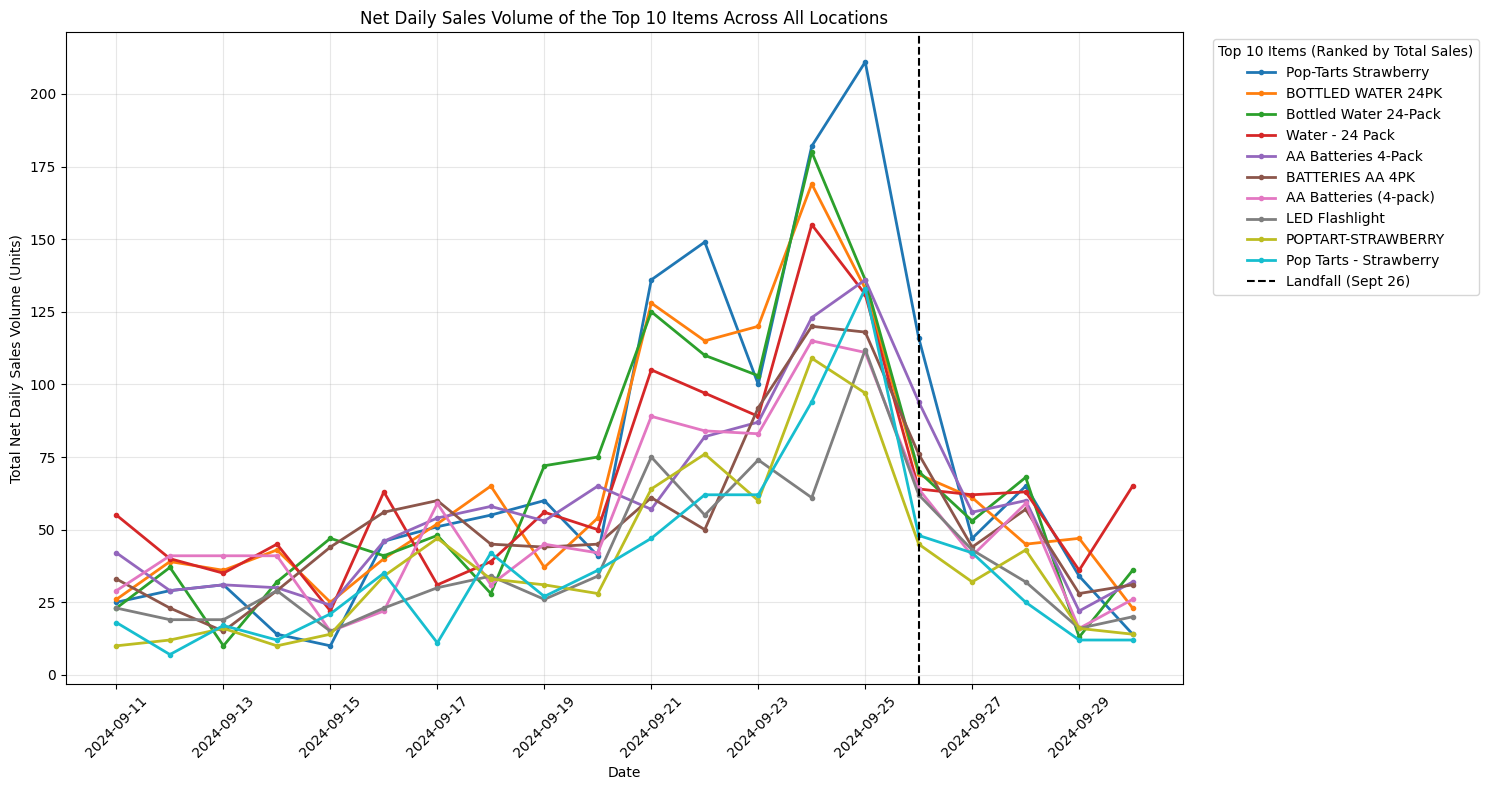

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

WEATHER_START = "2024-09-11"
WEATHER_END = "2024-10-01"

# Ensuring the clean transactions are recognized
assert len(transactions_clean) > 0, ("transactions_clean is empty, the data files didn't load in this session")

# Copy your sales data
sales = transactions_clean.copy()

# Establishing start and end date for the graph (10/01 is excluded)
start = pd.Timestamp(WEATHER_START).date()
end = pd.Timestamp(WEATHER_END).date()

# Extract the date from cleaned local timestamp, dropping NaTs
sales = sales.dropna(subset=["timestamp_local"]).copy()
sales["date"] = sales["timestamp_local"].dt.date

sales = sales[(sales["date"] >= start) & (sales["date"] < end)].copy()

# Ensuring clean sales data is recognized
assert len(sales) > 0, "no sales fall in the date range after parsing"

# Grouping net sales by item and date
item_daily_sales = (sales.groupby(["date", "product_name"])["quantity"].sum().reset_index())

all_dates = pd.date_range(
    start=WEATHER_START,
    end=WEATHER_END,
    inclusive="left",
    freq="D"
).date

fig, ax = plt.subplots(figsize=(15, 8))

#Pull total product sales
product_totals = (item_daily_sales.groupby("product_name")["quantity"].sum().sort_values(ascending=False))

# Select the top 10 best-selling items
top10_items = product_totals.head(10).index

# Plot the top ten and order from most sold to least sold
for item in top10_items:
    group = item_daily_sales[item_daily_sales["product_name"] == item]
    daily = group.set_index("date")["quantity"].reindex(all_dates, fill_value=0)
    ax.plot(all_dates, daily, marker="o", linewidth=2, markersize=3, label=item)

# Mark landfall on the graph
LANDFALL = pd.Timestamp("2024-09-26")
ax.axvline(LANDFALL, color="black", linestyle="--", label="Landfall (Sept 26)")

# Set axis and legend labels
ax.set_title("Net Daily Sales Volume of the Top 10 Items Across All Locations")
ax.set_xlabel("Date")
ax.set_ylabel("Total Net Daily Sales Volume (Units)")
ax.legend(title="Top 10 Items (Ranked by Total Sales)", bbox_to_anchor=(1.02, 1), loc="upper left")

ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 6 — Self-check

**TODO:** fill in the real values. The checks are shape checks; they cannot verify your analysis is right, only that you have gotten far enough to have one.

In [22]:
progress = {
    'rows_after_cleaning': len(transactions_clean),
    'decisions_logged': len(decision_log),
    'canonical_products': len(set(sku_to_canonical.values())),
    'weather_api_rows': None,           # TODO: rows returned by your API call
    'repo_url': 'https://github.com/ayanrasulova/ds2002-midterm',
    'notebook_runs_clean': True,
}

def check(items):
    ok = True
    for label, value in items.items():
        good = not (value is None or value is False
                    or (isinstance(value, str) and value.startswith('TODO')))
        print('PASS' if good else 'FAIL', '-', label, '=', value)
        ok = ok and good
    print()
    print('checkpoint complete:', ok)
    return ok

check(progress)

PASS - rows_after_cleaning = 25402
PASS - decisions_logged = 10
PASS - canonical_products = 20
FAIL - weather_api_rows = None
PASS - repo_url = https://github.com/ayanrasulova/ds2002-midterm
PASS - notebook_runs_clean = True

checkpoint complete: False


False

### 7 — Risk and plan

Two questions, answered concretely.

**a)** What is the single most likely thing to go wrong in the next two weeks? Name a specific technical or team problem, not "running out of time."

**b)** What are you doing about it this week? Name who is doing it and by when.

**Biggest risk:** The weather API call and timezone join are still unfinished, which could delay the weather and sales analysis.

**Plan, with an owner and a date:** Andrew owns the weather API work in the team charter. A due date has not been recorded yet.

### 8 — Where each question stands

**TODO:** mark each of the five questions. Use the owners from your charter. Be honest — this is the section I read first.

| Question | Status | Who owns it |
|---|---|---|
| Q1 demand surge | not started / in progress / draft answer | _..._ |
| Q2 SKU consolidation | _in progress_ | _ayan_ |
| Q3 weather correlation | _in progress_ | _andrew_ |
| Q4 store and geography | _..._ | _..._ |
| Q5 signal or artifact | _..._ | _..._ |

At the end of week 1, "not started" on Q4 and Q5 is expected. "Not started" on all five means come find me on Monday.